
#### Feature engineering

**Inputs:** `data/processed/clean.csv`, `returns.csv`, `macro.csv` and `data/interim/stocks_close.csv`, `merged.csv`

---

**Outputs:** `data/processed/features.csv` (with a `split` column), `feature_meta.json`, `reports/feature_dictionary.csv`, and two figures in `reports/figures/`

In [16]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, INTERIM = ROOT / "data" / "processed", ROOT / "data" / "interim"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
ANN = 252   # trading days per year

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"feat_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

clean = pd.read_csv(PROC / "clean.csv", index_col="Date", parse_dates=True)
rets = pd.read_csv(PROC / "returns.csv", index_col="Date", parse_dates=True).reindex(clean.index)
stocks = pd.read_csv(INTERIM / "stocks_close.csv", index_col="Date", parse_dates=True).reindex(clean.index)

print("clean   :", clean.shape, clean.index.min().date(), "to", clean.index.max().date())
print("returns :", rets.shape)
print("stocks  :", stocks.shape)

clean   : (4572, 11) 2008-03-03 to 2026-10-27
returns : (4572, 11)
stocks  : (4572, 15)


inspecting inputs

In [17]:
stock_ret_raw = np.log(stocks).diff()
stock_check = pd.DataFrame({
    "first_valid": stocks.apply(lambda s: s.first_valid_index().date()),
    "missing_%": (stocks.isna().mean() * 100).round(2),
    "worst_day_%": (stock_ret_raw.min() * 100).round(1),
    "best_day_%": (stock_ret_raw.max() * 100).round(1),
    "days_beyond_20%": (stock_ret_raw.abs() > 0.20).sum(),
})
display(stock_check)

stocks = stocks.ffill(limit=5)   # a few remaining holiday gaps only
stock_ret = np.log(stocks).diff()
print("Stocks with data on every date after fill:", int((stocks.isna().sum() == 0).sum()), "of", stocks.shape[1])

,first_valid,missing_%,worst_day_%,best_day_%,days_beyond_20%
reliance,2008-03-03,0.0,-17.8,19.4,0
hdfcbank,2008-03-03,0.0,-13.5,15.1,0
icicibank,2008-03-03,0.0,-22.1,20.7,2
infy,2008-03-03,0.0,-23.9,15.5,1
tcs,2008-03-03,0.0,-11.3,14.4,0
itc,2008-03-03,0.0,-13.7,10.5,0
lt,2008-03-03,0.0,-17.8,21.9,1
sbin,2008-03-03,0.0,-15.6,24.4,1
bhartiartl,2008-03-03,0.0,-13.6,22.7,1
hindunilvr,2008-03-03,0.0,-9.3,16.0,0


Stocks with data on every date after fill: 15 of 15


nifty momentum


In [18]:
registry = []
F = pd.DataFrame(index=clean.index)          # Indian features: known at the Indian close of day t

def add(frame, name, series, group, description):
    frame[name] = series
    registry.append({"feature": name, "group": group, "description": description})

n = rets["nifty50"]
add(F, "nifty_ret_1d", n, "indian", "Nifty 1-day log return")
add(F, "nifty_ret_5d", n.rolling(5).sum(), "indian", "Nifty 5-day log return")
add(F, "nifty_ret_21d", n.rolling(21).sum(), "indian", "Nifty 21-day log return")

check = np.log(clean["nifty50"] / clean["nifty50"].shift(21))
print("Max difference, rolling sum vs price ratio (21 days):", round(float((F["nifty_ret_21d"] - check).abs().max()), 6))
assert (F["nifty_ret_21d"] - check).abs().max() < 1e-4

Max difference, rolling sum vs price ratio (21 days): 4e-06


realised volatility

In [19]:
for w in (10, 21, 63):
    add(F, f"nifty_vol_{w}d", n.rolling(w).std() * np.sqrt(ANN), "indian", f"Nifty {w}-day realised volatility, annualised")

assert (F[["nifty_vol_10d", "nifty_vol_21d", "nifty_vol_63d"]].dropna() > 0).all().all()
print("Correlation of 21-day volatility with India VIX:", round(F["nifty_vol_21d"].corr(clean["india_vix"]), 2))

Correlation of 21-day volatility with India VIX: 0.87


drawdown from running peak

In [20]:
full_nifty = pd.read_csv(INTERIM / "merged.csv", index_col="Date", parse_dates=True)["nifty50"].dropna()
drawdown = (full_nifty / full_nifty.cummax() - 1).reindex(clean.index)
add(F, "nifty_drawdown", drawdown, "indian", "Distance below the all-time high (peak taken from Jan 2008)")

assert (drawdown <= 1e-12).all()
print("Deepest drawdown: %.1f%% on %s" % (drawdown.min() * 100, drawdown.idxmin().date()))
print("Days at a new high (drawdown = 0):", int((drawdown.abs() < 1e-12).sum()))

Deepest drawdown: -59.9% on 2008-10-27
Days at a new high (drawdown = 0): 312


moving average gaps

In [21]:
for w in (21, 63):
    add(F, f"nifty_ma_gap_{w}d", np.log(clean["nifty50"] / clean["nifty50"].rolling(w).mean()), "indian",
        f"Log distance of Nifty from its {w}-day average")

print("First date a 63-day window is complete :", clean.index[62].date())
print("First date a 200-day window is complete:", clean.index[199].date(), "(would remove the 2008 crash)")

First date a 63-day window is complete : 2008-06-06
First date a 200-day window is complete: 2008-12-30 (would remove the 2008 crash)


rolling skewness and kurtosis

In [22]:
add(F, "nifty_skew_63d", n.rolling(63).skew(), "indian", "Skewness of Nifty daily returns over 63 days")
add(F, "nifty_kurt_63d", n.rolling(63).kurt(), "indian", "Excess kurtosis of Nifty daily returns over 63 days")
print("Share of days with excess kurtosis above 0:", round(float((F["nifty_kurt_63d"].dropna() > 0).mean() * 100), 1), "%")

Share of days with excess kurtosis above 0: 72.8 %


India VIX and Bank Nifty relative strength


In [23]:
add(F, "vix_level", clean["india_vix"], "indian", "India VIX level")
add(F, "vix_chg_5d", rets["india_vix"].rolling(5).sum(), "indian", "5-day log change in India VIX")
add(F, "banknifty_rel_21d", rets["banknifty"].rolling(21).sum() - n.rolling(21).sum(), "indian",
    "Bank Nifty minus Nifty 21-day log return")

assert (F["vix_level"] > 0).all()
print("Largest 5-day VIX jumps:")
print(F["vix_chg_5d"].nlargest(3).round(2).to_string())

Largest 5-day VIX jumps:
Date
2020-03-16    0.83
2020-03-13    0.79
2020-03-17    0.71


Average pairwise stock correlation

In [24]:
def avg_pairwise_corr(ret, window):
    """Mean correlation over all stock pairs, using only the last `window` days."""
    k = ret.shape[1]
    rc = ret.rolling(window).corr()                       # one k x k matrix per date
    arr = rc.to_numpy().reshape(len(ret), k, k)
    iu = np.triu_indices(k, k=1)
    pairs = arr[:, iu[0], iu[1]]
    with np.errstate(all="ignore"):
        out = np.where(np.isnan(pairs).all(axis=1), np.nan, np.nanmean(pairs, axis=1))
    return pd.Series(out, index=ret.index)

stock_corr = avg_pairwise_corr(stock_ret, 21)
add(F, "stock_corr_21d", stock_corr, "indian", "Average pairwise correlation of 15 large-cap stocks, 21 days")

s = stock_corr.dropna()
assert s.between(-1, 1).all()
print("Mean correlation, Sep 2008 to Mar 2009 (stress):", round(s.loc["2008-09-01":"2009-03-31"].mean(), 2))
print("Mean correlation, 2017 (calm)                  :", round(s.loc["2017-01-01":"2017-12-31"].mean(), 2))
print("Mean correlation, Mar 2020 (Covid crash)       :", round(s.loc["2020-03-01":"2020-03-31"].mean(), 2))

Mean correlation, Sep 2008 to Mar 2009 (stress): 0.5
Mean correlation, 2017 (calm)                  : 0.16
Mean correlation, Mar 2020 (Covid crash)       : 0.6


Global and currency features

In [25]:
G = pd.DataFrame(index=clean.index)
for col, label in [("usdinr", "USD/INR"), ("brent", "Brent"), ("gold", "Gold"), ("sp500", "S&P 500")]:
    add(G, f"{col}_ret_21d", rets[col].rolling(21).sum(), "global_shifted", f"{label} 21-day log return (shifted 1 day)")
add(G, "us10y_level", clean["us10y"], "global_shifted", "US 10-year yield level, percent (shifted 1 day)")

G_unshifted = G.copy()
G = G.shift(1)                                         # only what was known at the previous close
print("Global features:", list(G.columns))

Global features: ['usdinr_ret_21d', 'brent_ret_21d', 'gold_ret_21d', 'sp500_ret_21d', 'us10y_level']


Macro feature: change in the RBI repo rate

In [26]:
MACRO_PATH = PROC / "macro.csv"
M = pd.DataFrame(index=clean.index)
if MACRO_PATH.exists():
    macro = pd.read_csv(MACRO_PATH, index_col="Date", parse_dates=True).reindex(clean.index)
    add(M, "repo_change_63d", macro["repo_change_63d"], "macro",
        "Change in RBI repo rate over 63 trading days, percentage points (not shifted)")
    print("Share of days with a non-zero change:", round(float((M["repo_change_63d"] != 0).mean() * 100), 1), "%")
    print("Value on the last date:", float(M["repo_change_63d"].iloc[-1]))
else:
    print("macro.csv not found: macro feature skipped. Run: python -m src.macro")
MACRO_FEATURES = list(M.columns)

Share of days with a non-zero change: 51.7 %
Value on the last date: 0.25


Combine, drop warm-up rows, and test for look-ahead


In [27]:
features = pd.concat([F, G, M], axis=1)
rows_before = len(features)
features = features.replace([np.inf, -np.inf], np.nan).dropna()
print(f"Rows before: {rows_before} | after warm-up drop: {len(features)} | dropped: {rows_before - len(features)}")
print("First usable date:", features.index.min().date(), "| last:", features.index.max().date())
assert features.isna().sum().sum() == 0 and features.index.is_monotonic_increasing and features.index.is_unique

GLOBAL_FEATURES = list(G.columns)
INDIAN_FEATURES = list(F.columns)

# Test 1: a shifted feature equals the unshifted value of the previous row
t = features.index[len(features) // 2]
prev_t = clean.index[clean.index.get_loc(t) - 1]
for col in GLOBAL_FEATURES:
    assert np.isclose(features.loc[t, col], G_unshifted.loc[prev_t, col]), f"{col} not shifted"
print("OK  every global feature on", t.date(), "uses the value from", prev_t.date())

# Test 2: no global feature may match its same-day value on most rows
same_day = (features[GLOBAL_FEATURES] == G_unshifted.reindex(features.index)[GLOBAL_FEATURES]).mean()
assert (same_day < 0.5).all()
print("OK  no global feature equals its same-day value")

# Test 3: changing the last day's prices must not change any earlier feature
check_px = clean["nifty50"].copy()
check_px.iloc[-1] *= 1.5
r_mod, r_base = np.log(check_px).diff(), np.log(clean["nifty50"]).diff()
assert np.isclose(r_mod.rolling(63).std().iloc[-2], r_base.rolling(63).std().iloc[-2])
assert np.isclose(r_mod.rolling(21).sum().iloc[-2], r_base.rolling(21).sum().iloc[-2])
print("OK  rolling windows only look backwards")

Rows before: 4572 | after warm-up drop: 4509 | dropped: 63
First usable date: 2008-06-09 | last: 2026-10-27
OK  every global feature on 2017-09-04 uses the value from 2017-09-01
OK  no global feature equals its same-day value
OK  rolling windows only look backwards


Time-ordered train / test label

In [28]:
TRAIN_END = "2017-12-31"
features["split"] = np.where(features.index <= TRAIN_END, "train", "test")

def describe_split(d):
    return pd.Series({
        "rows": len(d),
        "start": d.index.min().date(),
        "end": d.index.max().date(),
        "mean_vix": round(d["vix_level"].mean(), 1),
        "days_vix_above_25_%": round((d["vix_level"] > 25).mean() * 100, 1),
        "days_drawdown_below_-10%": round((d["nifty_drawdown"] < -0.10).mean() * 100, 1),
        "days_drawdown_below_-20%": round((d["nifty_drawdown"] < -0.20).mean() * 100, 1),
    })

display(features.groupby("split").apply(describe_split).T)

split,test,train
rows,2173,2336
start,2018-01-02,2008-06-09
end,2026-10-27,2017-12-29
mean_vix,16.9,22.0
days_vix_above_25_%,6.0,25.6
days_drawdown_below_-10%,15.2,50.3
days_drawdown_below_-20%,2.4,20.7


Feature dictionary and a quick look

21 features documented in reports/feature_dictionary.csv


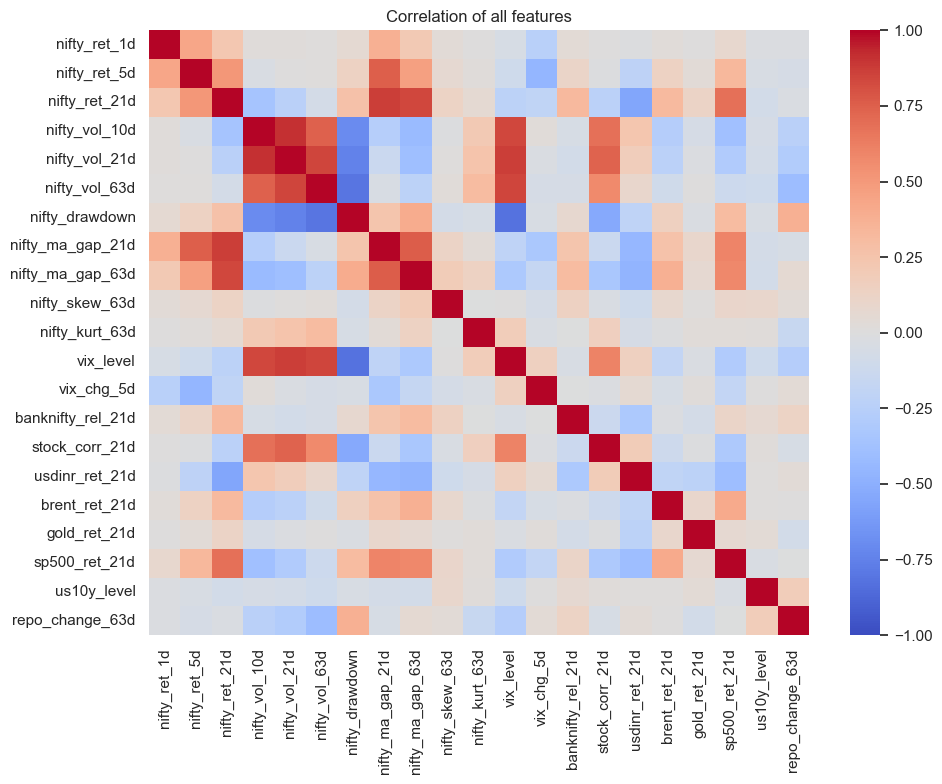


4 feature pairs with |correlation| > 0.85 (PCA will combine these):


,feature_1,feature_2,corr
67,nifty_vol_10d,nifty_vol_21d,0.91
49,nifty_ret_21d,nifty_ma_gap_21d,0.87
95,nifty_vol_21d,vix_level,0.87
116,nifty_vol_63d,vix_level,0.85


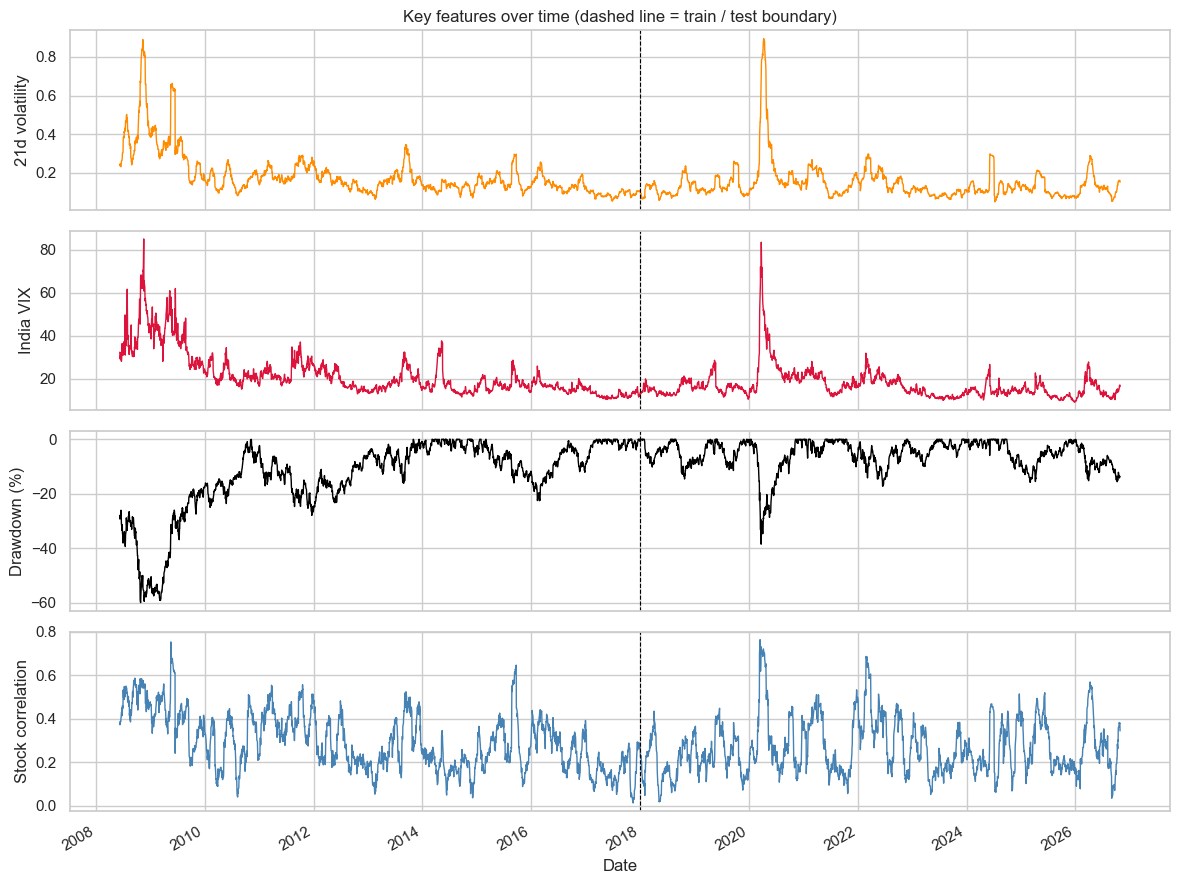

In [29]:
feature_dictionary = pd.DataFrame(registry)
feature_dictionary.to_csv(ROOT / "reports" / "feature_dictionary.csv", index=False)
print(f"{len(feature_dictionary)} features documented in reports/feature_dictionary.csv")

FEATURE_COLS = INDIAN_FEATURES + GLOBAL_FEATURES + MACRO_FEATURES
corr = features[FEATURE_COLS].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation of all features")
save_fig("correlation")

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().reset_index()
pairs.columns = ["feature_1", "feature_2", "corr"]
high = pairs[pairs["corr"].abs() > 0.85].sort_values("corr", key=abs, ascending=False)
print(f"\n{len(high)} feature pairs with |correlation| > 0.85 (PCA will combine these):")
display(high.round(2).head(12))

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
features["nifty_vol_21d"].plot(ax=axes[0], color="darkorange", linewidth=1); axes[0].set_ylabel("21d volatility")
features["vix_level"].plot(ax=axes[1], color="crimson", linewidth=1); axes[1].set_ylabel("India VIX")
(features["nifty_drawdown"] * 100).plot(ax=axes[2], color="black", linewidth=1); axes[2].set_ylabel("Drawdown (%)")
features["stock_corr_21d"].plot(ax=axes[3], color="steelblue", linewidth=1); axes[3].set_ylabel("Stock correlation")
for ax in axes:
    ax.axvline(pd.Timestamp(TRAIN_END), color="black", linestyle="--", linewidth=0.8)
axes[0].set_title("Key features over time (dashed line = train / test boundary)")
save_fig("timelines")

Save and verify the output

In [30]:
features[FEATURE_COLS + ["split"]].round(6).to_csv(PROC / "features.csv", index_label="Date")

meta = {
    "train_end": TRAIN_END,
    "indian_features": INDIAN_FEATURES,
    "global_features_shifted_1d": GLOBAL_FEATURES,
    "macro_features": MACRO_FEATURES,
    "note_us10y_level": "us10y_level can act as a calendar; consider dropping it if classifiers overfit",
}
with open(PROC / "feature_meta.json", "w") as f:
    json.dump(meta, f, indent=2)

saved = pd.read_csv(PROC / "features.csv", index_col="Date", parse_dates=True)
assert saved.drop(columns="split").isna().sum().sum() == 0
assert saved.drop(columns="split").select_dtypes(include="number").shape[1] == len(FEATURE_COLS)
print("Final shape:", saved.shape, "(rows x [features + split])")
print("Date range :", saved.index.min().date(), "to", saved.index.max().date())
print("Train rows :", int((saved["split"] == "train").sum()), "| Test rows:", int((saved["split"] == "test").sum()))
print("\nFeature list and data types:")
display(pd.DataFrame({"dtype": saved.dtypes.astype(str)}).join(feature_dictionary.set_index("feature")[["group"]]))

Final shape: (4509, 22) (rows x [features + split])
Date range : 2008-06-09 to 2026-10-27
Train rows : 2336 | Test rows: 2173

Feature list and data types:


,dtype,group
nifty_ret_1d,float64,indian
nifty_ret_5d,float64,indian
nifty_ret_21d,float64,indian
nifty_vol_10d,float64,indian
nifty_vol_21d,float64,indian
nifty_vol_63d,float64,indian
nifty_drawdown,float64,indian
nifty_ma_gap_21d,float64,indian
nifty_ma_gap_63d,float64,indian
nifty_skew_63d,float64,indian
